# Trajectory application

> Ambient: **scRNA_trajectory**

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd
import numpy as np

DATASET = "Ffar2"
target_gene = "Ffar2"
sample_col = "sample"
condition_col = "condition"
celltype_col = "celltype"
counts_layer = "counts"
stage_order = ["G0", "G1", "G2", "G3", "G4", "G5a", "G5b", "G5c"]
condition_palette = {"WT": "#4C72B0", "KO": "#DD8452"}

output_dir = Path(f"/media/tahila/DADOS/HD/2605_scNeu/scNeu{DATASET}")
adata = sc.read_h5ad(f"{output_dir}/06sx.Neu{DATASET}_annotated.h5ad")
ad_traj = adata.copy()

# Step 1 — Build and validate the global maturation topology with diffusion maps and PAGA

### Goal

Before calculating pseudotime, we first ask whether the **transcriptional structure of the dataset is consistent with the known neutrophil maturation sequence**:

**G0 → G1 → G2 → G3 → G4 → G5a/G5b → G5c**

where `G5a` and `G5b` represent alternative states emerging after G4 and both subsequently connect to G5c.

This step is important because trajectory inference should not be used simply to force cells into a predefined biological order. Instead, the topology inferred from transcriptomic similarity should first be checked against prior biological knowledge [Wolf, 2019; Haghverdi, 2016].

### Why use diffusion maps?

Diffusion maps represent cells according to their connectivity through the cell–cell neighborhood graph rather than only their Euclidean distance in PCA space. This makes them particularly suitable for continuous biological processes such as differentiation and maturation [Haghverdi, 2016].

The diffusion representation will later also provide the basis for **Diffusion Pseudotime (DPT)**.

### Why use PAGA?

**PAGA (Partition-based Graph Abstraction)** summarizes the single-cell neighborhood graph into a simpler graph in which:

* each node represents a cell population;
* edges represent the statistical connectivity between populations;
* stronger edges indicate stronger evidence that two populations are connected in the underlying single-cell manifold;
* weak/spurious connections can be removed by thresholding.

Unlike methods that force the data into a tree, PAGA can represent more complex topologies, including branching, disconnected regions, and non-tree structures [Wolf, 2019]. This is particularly useful here because `G5a` and `G5b` form alternative states rather than a simple strictly linear sequence.

At this stage, **PAGA does not establish directionality**. An edge between G3 and G4 means that these populations are transcriptionally connected; the biological direction `G3 → G4` comes from prior knowledge and will later be incorporated through the definition of G0 as the trajectory root.

### Representation used in this dataset

For this dataset, the trajectory will be inferred jointly using cells from both WT and KO. Therefore, the low-dimensional representation used to construct the graph should represent the **shared biological manifold across conditions**.

The existing integrated PCA can be used for this purpose, provided that `X_pca` corresponds to the Seurat-anchor-integrated representation used in the original analysis.

Importantly, the integrated representation is appropriate for **constructing the trajectory geometry**, but it should not later be used as the expression matrix for testing gene-expression differences between WT and KO. Gene-level statistical analyses should return to non-integrated expression/count data.

The categorical ordering is mainly useful for consistent plotting and summaries. It **does not imply that G5a precedes G5b**; they are biologically parallel states.

In [2]:
### Function 1 — Compute diffusion maps and PAGA

def ComputeDiffusionPaga(
    adata,
    group_col,
    use_rep="X_pca",
    n_neighbors=15,
    n_diffmap=15,
    initial_neighbors_key="trajectory_initial_neighbors",
    trajectory_neighbors_key="trajectory_neighbors",
    random_state=42,
):
    """
    adata : AnnData --> Annotated single-cell dataset.
    group_col : str --> Column defining groups represented as PAGA nodes.
    use_rep : str --> Initial low-dimensional representation.
    n_neighbors : int --> Number of neighbors used for graph construction.
    n_diffmap : int --> Number of diffusion components.
    initial_neighbors_key : str --> Key used for the initial neighbor graph.
    trajectory_neighbors_key : str --> Key used for the diffusion-space neighbor graph.
    random_state : int --> Random seed.
    """
    # check that the group column (PAGA nodes) exists in adata.obs
    if group_col not in adata.obs:
        raise KeyError(f"{group_col} not found in adata.obs.")

    # check that the initial low-dimensional representation (e.g. X_pca) exists in adata.obsm
    if use_rep not in adata.obsm:
        raise KeyError(f"{use_rep} not found in adata.obsm.")

    # Initial cell-cell graph
    # build the initial neighbor graph from use_rep (e.g. the integrated PCA)
    sc.pp.neighbors(
        adata,
        n_neighbors=n_neighbors,
        use_rep=use_rep,
        key_added=initial_neighbors_key,
        random_state=random_state,
    )

    # Diffusion representation
    # compute the diffusion map from the initial neighbor graph
    sc.tl.diffmap(
        adata,
        n_comps=n_diffmap,
        neighbors_key=initial_neighbors_key,
        random_state=random_state,
    )

    # Neighborhood graph in diffusion space
    # rebuild the neighbor graph, now using the diffusion space (X_diffmap)
    sc.pp.neighbors(
        adata,
        n_neighbors=n_neighbors,
        use_rep="X_diffmap",
        key_added=trajectory_neighbors_key,
        random_state=random_state,
    )

    # PAGA topology
    # compute the PAGA topology (connectivity between groups) using the diffusion-space graph
    sc.tl.paga(
        adata,
        groups=group_col,
        neighbors_key=trajectory_neighbors_key,
    )

    # store the parameters used in this step, for traceability and reproducibility
    adata.uns["trajectory_params"] = {
        "group_col": group_col,
        "use_rep": use_rep,
        "n_neighbors": n_neighbors,
        "n_diffmap": n_diffmap,
        "initial_neighbors_key": initial_neighbors_key,
        "trajectory_neighbors_key": trajectory_neighbors_key,
        "random_state": random_state,
    }

In [3]:
### Application
ComputeDiffusionPaga(
    adata=ad_traj,
    group_col="celltype",
    use_rep="X_pca",
    n_neighbors=15,
    n_diffmap=15,
)

In [4]:
### Function 3 — Plot the PAGA topology

import matplotlib.pyplot as plt  # needed to control the figure/axis of the plot


def PlotPagaTrajectory(
    adata,
    group_col,
    threshold=0.03,
    figsize=(6, 6),
):
    """
    adata : AnnData --> Dataset containing a computed PAGA graph.
    group_col : str --> Group annotation represented by PAGA nodes.
    threshold : float --> Minimum connectivity displayed.
    figsize : tuple --> Figure size.
    """
    # create figure and axis with the given size
    fig, ax = plt.subplots(figsize=figsize)

    # plot the PAGA graph, showing only connections above the connectivity threshold
    sc.pl.paga(
        adata,
        color=group_col,
        threshold=threshold,
        frameon=False,
        ax=ax,
        show=False,
    )

    # display the figure
    plt.show()

    # return the axis, so it can be customized further outside the function
    return ax

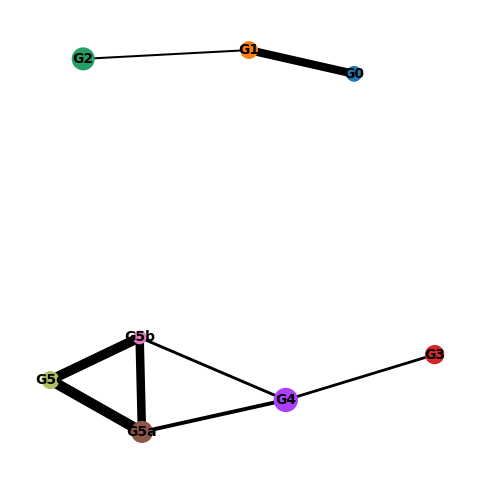

<Axes: >

In [5]:
### Application
PlotPagaTrajectory(
    adata=ad_traj,
    group_col="celltype",
    threshold=0.03,
)

### What should we expect?

A biologically coherent topology would approximately support:

```text
G0 — G1 — G2 — G3 — G4
                     /  \
                   G5a  G5b
                     \  /
                     G5c
```

It does **not need to reproduce this exact drawing**. The graph layout itself is arbitrary; what matters is the **pattern and relative strength of the edges**.

Particularly important observations will be:

* whether G0 connects primarily to early states;
* whether G1–G4 form a broadly sequential structure;
* whether G5a and G5b connect to G4;
* whether G5c connects to the late populations;
* whether unexpectedly strong shortcuts such as `G0–G5c` occur;
* whether any stage becomes disconnected.

We should inspect this result **before calculating pseudotime**. If the PAGA topology is biologically coherent, **Step 2 will define a representative G0 root cell and calculate DPT pseudotime** [Haghverdi, 2016; Wolf, 2019].


# Step 2 — Define the trajectory root and compute Diffusion Pseudotime (DPT)

### Goal

After confirming with PAGA that the global transcriptomic topology is compatible with the expected neutrophil maturation structure, the next step is to obtain a **continuous maturation coordinate** for each cell.

For this dataset, the biological starting population is already known:

**G0 → G1 → G2 → G3 → G4 → G5a/G5b → G5c**

Therefore, we do not need to infer which population represents the beginning of the trajectory. We only need to select a representative cell within **G0** and use it as the DPT root.

**Diffusion Pseudotime (DPT)** orders cells according to diffusion-based distances from a specified root cell, providing a continuous coordinate along the inferred cellular manifold [Haghverdi, 2016]. DPT requires a diffusion map, which was already calculated in Step 1. ([Scanpy][1])

The resulting pseudotime is a **relative transcriptional progression**, not chronological time. A value of 0.8 does not mean that a cell is twice as old as a cell at 0.4 [Haghverdi, 2016].

### Why DPT is appropriate here

DPT is sufficient for the present goal because:

* G0 is a biologically defined starting state;
* we want one continuous maturation axis shared by WT and KO;
* fate probabilities are not required;
* the `G5a/G5b` branching structure is assessed separately with PAGA.

Scanpy currently recommends using DPT primarily for pseudotime ordering and handling branching structure separately with PAGA rather than relying on the older hierarchical branching functionality of DPT [Wolf, 2019]. ([Scanpy][1])

---

### Select a representative G0 root cell

Scanpy technically requires only **one root-cell index** in:

```python
ad_traj.uns["iroot"]
```

The official Scanpy trajectory tutorial selects a biologically defined stem/progenitor cell and then runs DPT. ([Scanpy][2])

Because G0 contains many cells, we will avoid selecting an arbitrary or peripheral G0 cell. Instead, we select the G0 cell closest to the median position of G0 in diffusion space.

This is a **practical robustness heuristic**, not a requirement of the DPT method.

This helper is generic enough to keep in `sctools`, since it can also be reused whenever a representative cell from an annotated population is needed.

In [6]:
def SelectRepresentativeCell(
    adata,
    group_col,
    group,
    rep_key="X_diffmap",
    n_components=10,
):
    """
    adata : AnnData --> Annotated single-cell dataset.
    group_col : str --> Column containing population annotations.
    group : str --> Population used for representative-cell selection.
    rep_key : str --> Low-dimensional representation used for selection.
    n_components : int --> Number of dimensions used to define the population center.
    """
    mask = adata.obs[group_col].astype(str).eq(group).to_numpy()

    cells = adata.obs_names[mask]
    X = adata.obsm[rep_key][mask]

    if len(cells) == 0:
        raise ValueError(f"No cells found for group: {group}")

    # Skip the first diffusion component
    start = 1 if rep_key == "X_diffmap" else 0
    X = X[:, start:start + n_components]

    center = np.median(X, axis=0)
    distances = np.linalg.norm(X - center, axis=1)

    return cells[np.argmin(distances)]

In [7]:
### Application
root_cell = SelectRepresentativeCell(
    adata=ad_traj,
    group_col="celltype",
    group="G0",
    rep_key="X_diffmap",
    n_components=10,
)

print("Root cell:", root_cell)
print("Cell type:", ad_traj.obs.loc[root_cell, "celltype"])

Root cell: 36711955-K1
Cell type: G0


The important check is simply:

```text
Cell type: G0
```

## Compute DPT

I would **not create a custom `sctools` wrapper for this step**. `scanpy.tl.dpt()` already performs exactly what we need, so wrapping it would only duplicate Scanpy.

Set the selected cell as the root:

```python
ad_traj.uns["iroot"] = ad_traj.obs_names.get_loc(root_cell)
```

Then calculate DPT:


In [8]:
ad_traj.uns["iroot"] = ad_traj.obs_names.get_loc(root_cell)

sc.tl.dpt(
    ad_traj,
    n_dcs=10,
    n_branchings=0,
    neighbors_key="trajectory_neighbors",
)

Scanpy stores the result directly in:

```python
ad_traj.obs["dpt_pseudotime"]
```

`n_dcs=10` is the current Scanpy default for the number of diffusion components contributing to DPT. Since we computed 15 diffusion components in Step 1, there are sufficient components available for this calculation. ([Scanpy][1])

We explicitly use:

```python
neighbors_key="trajectory_neighbors"
```

so DPT operates on the diffusion-space neighborhood graph created in Step 1 rather than another neighbor graph that may already exist in the `AnnData`. Scanpy supports this through the `neighbors_key` argument. ([Scanpy][3])

And:

```python
n_branchings=0
```

because we are using **PAGA for topology/branch structure** and DPT only for the continuous pseudotime coordinate.

---

## Quick visualization

At this stage, only perform a basic sanity check:

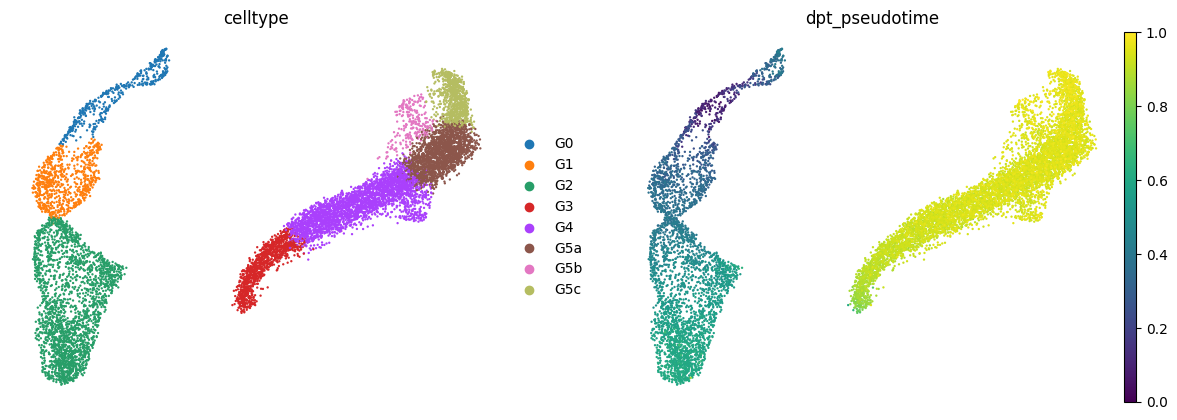

In [9]:
sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

We expect low DPT values around G0 and progressively higher values toward the mature populations.

The UMAP itself does **not** define the trajectory; it is only being used to visualize the DPT values on the existing embedding.

---

### Output of this step

The only new variable required downstream is:

```python
ad_traj.obs["dpt_pseudotime"]
```

---

### Operational summary of Step 2:

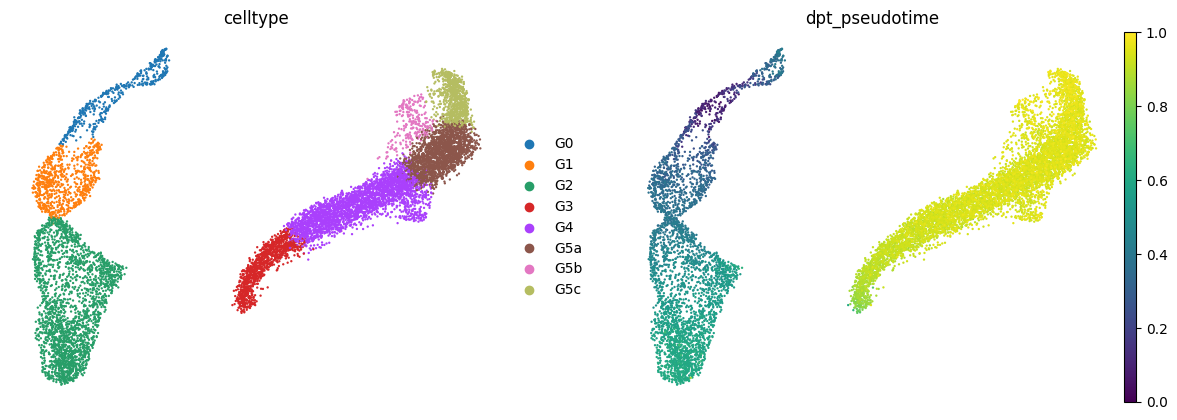

In [10]:
root_cell = SelectRepresentativeCell(
    ad_traj,
    group_col="celltype",
    group="G0",
    rep_key="X_diffmap",
)

ad_traj.uns["iroot"] = ad_traj.obs_names.get_loc(root_cell)

sc.tl.dpt(
    ad_traj,
    n_dcs=10,
    n_branchings=0,
    neighbors_key="trajectory_neighbors",
)

sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

# Step 3 — Validate the biological coherence of the inferred pseudotime

### Goal

Before using DPT in downstream analyses, we need to verify that the inferred continuous coordinate is **consistent with the known neutrophil maturation process**:

**G0 → G1 → G2 → G3 → G4 → G5a/G5b → G5c**

This step is a **sanity/biological-consistency check**, not an independent validation of the cell annotations.

Because the maturation labels were themselves defined from transcriptional information, agreement between `celltype` and DPT should not be interpreted as independent experimental evidence that the trajectory is correct. Instead, we are checking that the continuous manifold inferred by DPT is compatible with the biological structure already established for the dataset [Haghverdi, 2016; Wolf, 2019].

We mainly want to confirm that:

* G0 occupies the beginning of pseudotime;
* G1–G4 progressively move toward later pseudotime;
* G5a and G5b occur in late regions without requiring one to precede the other;
* G5c occupies the latest portion of the maturation continuum;
* the same general ordering is recognizable in all biological samples.

Some overlap between adjacent populations is expected because differentiation and maturation are continuous processes rather than perfectly discrete transcriptional states [Haghverdi, 2016].

---

## 3.1 — Visualize pseudotime on the existing UMAP

The UMAP is used here only for visualization. DPT was calculated from the diffusion-based neighborhood graph, not from the UMAP coordinates.



[1]: https://scanpy.readthedocs.io/en/latest/api/scanpy.tl.dpt.html?utm_source=chatgpt.com "scanpy.tl.dpt - Read the Docs"
[2]: https://scanpy.readthedocs.io/en/latest/tutorials/trajectories/paga-paul15.html?utm_source=chatgpt.com "Trajectory inference for hematopoiesis in mouse - Scanpy"
[3]: https://scanpy.readthedocs.io/en/stable/api/scanpy.tl.dpt.html?utm_source=chatgpt.com "scanpy.tl.dpt - Read the Docs"


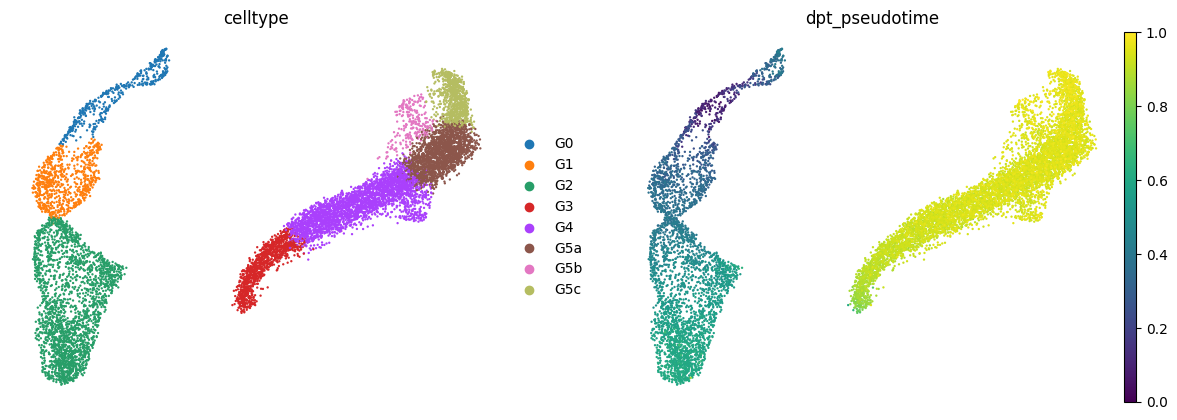

In [11]:
sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

We should see a broadly continuous transition from low pseudotime around G0 toward higher values in the mature populations.

A perfect geometric gradient on UMAP is **not required**, because UMAP can distort global distances and topology [Wolf, 2019].

---

## 3.2 — Inspect pseudotime distributions across maturation stages

The most informative plot for this step is the distribution of DPT values within each known maturation state.


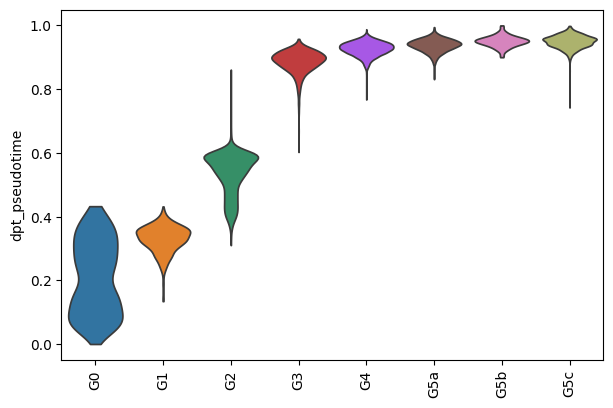

In [12]:
sc.pl.violin(
    ad_traj,
    keys="dpt_pseudotime",
    groupby="celltype",
    order=stage_order,
    rotation=90,
    stripplot=False,
)

The expected pattern is approximately:

```text
G0 < G1 < G2 < G3 < G4 < G5a/G5b < G5c
```

However, we should **not expect complete separation** between stages.

In particular, `G5a` and `G5b` are alternative late states, so their distributions can overlap considerably and their median pseudotimes do not need to be identical.

We should also avoid interpreting the categorical ordering:

```text
G5a → G5b
```

because that transition is not part of the biological model.

---

## 3.3 — Summarize pseudotime by maturation stage

A simple table is enough; there is no need for a dedicated `sctools` function.

In [13]:
pseudotime_summary = (
    ad_traj.obs
    .groupby("celltype", observed=True)["dpt_pseudotime"]
    .agg(
        n="size",
        median="median",
        mean="mean",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(stage_order)
)

pseudotime_summary

,n,median,mean,q25,q75
celltype,,,,,
G0,455,0.206337,0.208375,0.102357,0.311639
G1,772,0.335717,0.329710,0.306758,0.358875
G2,2328,0.554106,0.534572,0.495110,0.586731
G3,1102,0.892260,0.885809,0.869547,0.909911
G4,2924,0.929060,0.927021,0.913805,0.942669
G5a,1929,0.939908,0.937968,0.926335,0.951631
G5b,245,0.950609,0.950272,0.940154,0.961026
G5c,815,0.950925,0.949393,0.937189,0.962510


The median is particularly useful for checking the overall progression, while `q25` and `q75` show how much neighboring states overlap.

---

## 3.4 — Check consistency across biological samples

Because the trajectory will later be used to compare WT and KO, we should verify that the maturation ordering is not driven by only one mouse.

Again, a simple summary is sufficient.


In [14]:
pseudotime_by_sample = (
    ad_traj.obs
    .groupby(
        ["sample", "celltype"],
        observed=True,
    )["dpt_pseudotime"]
    .median()
    .unstack("celltype")
    .reindex(columns=stage_order)
)

pseudotime_by_sample

celltype,G0,G1,G2,G3,G4,G5a,G5b,G5c
sample,,,,,,,,
K1,0.162759,0.338133,0.560403,0.894307,0.932050,0.940226,0.955729,0.950792
K2,0.208792,0.331707,0.548423,0.894870,0.930055,0.940887,0.953748,0.955224
W1,0.206337,0.313132,0.572426,0.889347,0.928222,0.940760,0.948540,0.948154
W2,0.224673,0.353671,0.545134,0.890815,0.927021,0.937654,0.947547,0.949627


Each row represents one biological sample.

We want the same broad progression to be recognizable in all four animals:

```text
G0 → G1 → G2 → G3 → G4 → late states → G5c
```

The absolute median pseudotime values do not need to be identical between animals.

---

## 3.5 — Optional: check WT and KO separately

This is useful as a quick visualization before moving to condition comparisons.

In [15]:
pseudotime_by_condition = (
    ad_traj.obs
    .groupby(
        ["condition", "celltype"],
        observed=True,
    )["dpt_pseudotime"]
    .median()
    .unstack("celltype")
    .reindex(columns=stage_order)
)

pseudotime_by_condition

celltype,G0,G1,G2,G3,G4,G5a,G5b,G5c
condition,,,,,,,,
KO,0.197011,0.333650,0.551981,0.894726,0.930653,0.940634,0.953926,0.953642
WT,0.214823,0.337329,0.555190,0.890362,0.927615,0.939193,0.947666,0.948454


This does **not test whether WT and KO differ statistically**. It only verifies that both conditions are being represented along the same biologically interpretable maturation axis.

If these results show a coherent **G0 → G5c maturation continuum in all four samples**, we consider the DPT axis sufficiently supported for downstream use [Haghverdi, 2016].
---

## Minimal operational Step 3

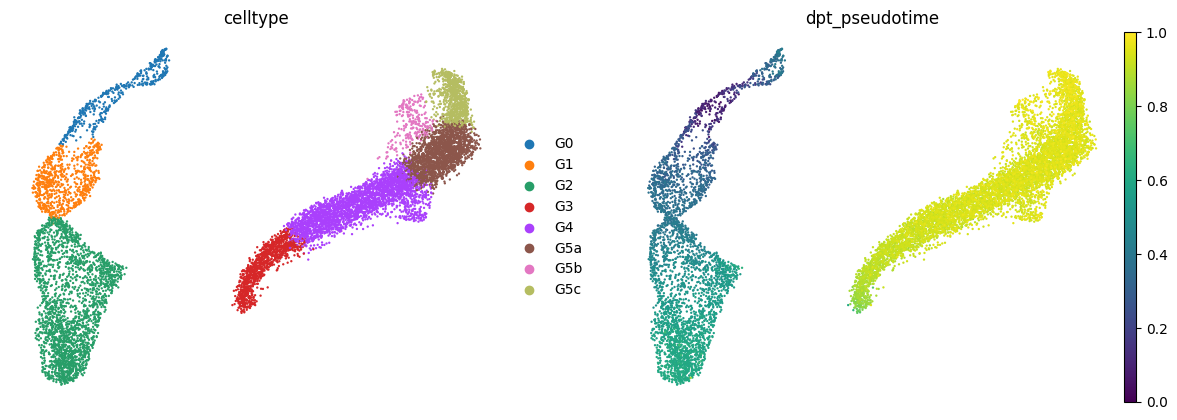

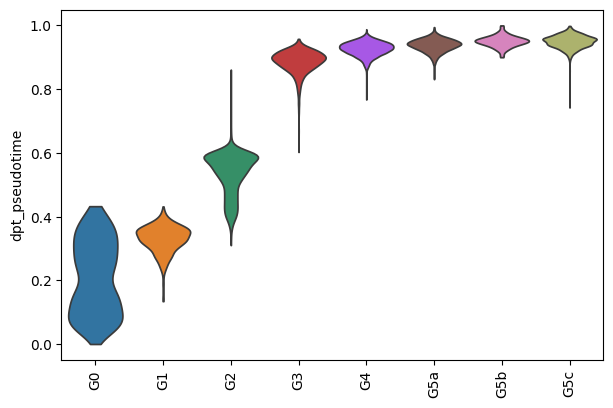

,n,median,q25,q75
celltype,,,,
G0,455,0.206337,0.102357,0.311639
G1,772,0.335717,0.306758,0.358875
G2,2328,0.554106,0.495110,0.586731
G3,1102,0.892260,0.869547,0.909911
G4,2924,0.929060,0.913805,0.942669
G5a,1929,0.939908,0.926335,0.951631
G5b,245,0.950609,0.940154,0.961026
G5c,815,0.950925,0.937189,0.962510


celltype,G0,G1,G2,G3,G4,G5a,G5b,G5c
sample,,,,,,,,
K1,0.162759,0.338133,0.560403,0.894307,0.932050,0.940226,0.955729,0.950792
K2,0.208792,0.331707,0.548423,0.894870,0.930055,0.940887,0.953748,0.955224
W1,0.206337,0.313132,0.572426,0.889347,0.928222,0.940760,0.948540,0.948154
W2,0.224673,0.353671,0.545134,0.890815,0.927021,0.937654,0.947547,0.949627


In [16]:
# DPT on UMAP
sc.pl.umap(
    ad_traj,
    color=["celltype", "dpt_pseudotime"],
    cmap="viridis",
    frameon=False,
    ncols=2,
)

# DPT distribution across maturation stages
sc.pl.violin(
    ad_traj,
    keys="dpt_pseudotime",
    groupby="celltype",
    order=stage_order,
    rotation=90,
    stripplot=False,
)

# Stage-level summary
pseudotime_summary = (
    ad_traj.obs
    .groupby("celltype", observed=True)["dpt_pseudotime"]
    .agg(
        n="size",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(stage_order)
)

display(pseudotime_summary)

# Check each biological replicate
pseudotime_by_sample = (
    ad_traj.obs
    .groupby(["sample", "celltype"], observed=True)["dpt_pseudotime"]
    .median()
    .unstack("celltype")
    .reindex(columns=stage_order)
)

display(pseudotime_by_sample)

# Step 4 — TradeSeq - Identify condition-dependent gene dynamics along DPT

Sim. Vamos **voltar exatamente ao núcleo que já rodou no seu computador e gerou os plots de Ffar2, Fosb e Dusp1**. Não vou incluir agora `l2fc`, `predictSmooth`, métricas de separação, `converged`, `sce=True` nem uma segunda chamada do `conditionTest`.

O Step 4 fica apenas:

```text
raw counts + DPT + condition
        ↓
min_cells = 20
        ↓
fitGAM()
        ↓
conditionTest()
        ↓
BH correction
        ↓
PlotTradeSeqConditionGene()
```

O `min_cells=20` continua sendo **nosso filtro computacional**, não uma regra do tradeSeq. O restante é o teste oficial do tradeSeq para modelar expressão ao longo do pseudotime [Van den Berge, 2020].

---

### Goal

The main question is:

> **Which genes show different expression dynamics along neutrophil maturation between WT and KO?**

Instead of comparing WT and KO independently at discrete maturation stages, this analysis uses the **continuous DPT pseudotime** calculated in Steps 1–3.

For each gene, condition-specific expression trajectories are modeled along pseudotime:

```text
WT: expression = fWT(pseudotime)
KO: expression = fKO(pseudotime)
````

`tradeSeq` models gene counts along pseudotime using negative-binomial generalized additive models (NB-GAMs) [Van den Berge, 2020].

The analysis uses raw counts and does **not require genes to be significant in the previous stage-specific differential-expression analysis**.

### Input

```text
ad_traj.layers["QC_filtered"]  → raw counts
ad_traj.obs["dpt_pseudotime"] → continuous maturation coordinate
ad_traj.obs["condition"]       → WT / KO
```

Because a single common maturation trajectory is modeled, all cells receive lineage weight equal to `1`.

### Gene filtering

Genes detected in fewer than 20 cells are excluded before GAM fitting.

This is a **practical computational filter**, not an official tradeSeq threshold or a universal biological cutoff. Its purpose is to avoid fitting complex GAMs to extremely sparse genes with little information about continuous expression dynamics.

### Statistical interpretation

`conditionTest()` tests whether the fitted expression trajectories differ between conditions.

Because the model is fitted at the cell level, these results should be interpreted primarily as **trajectory-based evidence for gene discovery and prioritization**, rather than as replicate-aware evidence of a genotype effect.

The existing pseudobulk analysis remains complementary evidence for reproducibility across biological samples.

````

---

# 4.1 Condition-dependent tradeSeq model

Essa é a **versão que devemos manter agora**:

In [18]:
def RunTradeSeqConditionDynamics(
    adata,
    counts_layer,
    pseudotime_col="dpt_pseudotime",
    condition_col="condition",
    condition_order=("WT", "KO"),
    min_cells=20,
    nknots=6,
    l2fc=0.0,
    n_cpus=4,
    seed=42,
):
    """
    Fit tradeSeq condition-specific NB-GAMs and run conditionTest.

    adata : AnnData --> Single-cell dataset containing raw counts and pseudotime.
    counts_layer : str --> Layer containing raw counts.
    pseudotime_col : str --> Column containing continuous pseudotime.
    condition_col : str --> Column containing experimental conditions.
    condition_order : tuple[str] --> Ordered condition levels.
    min_cells : int --> Minimum cells detecting a gene before GAM fitting.
    nknots : int --> Number of knots used by tradeSeq GAMs.
    n_cpus : int --> Number of CPUs used by tradeSeq.
    seed : int --> Random seed.
    l2fc : float --> Minimum log2 fold-change threshold used by conditionTest.

    Returns
    -------
    dict --> conditionTest results, fitted tradeSeq model, counts matrix and fitted genes.
    """
    import numpy as np
    import pandas as pd
    from scipy import sparse
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    # Keep cells with complete trajectory metadata
    mask = adata.obs[[pseudotime_col, condition_col]].notna().all(axis=1).to_numpy()

    X = adata.layers[counts_layer][mask]
    cells = adata.obs_names[mask].astype(str)

    # CUSTOM preprocessing: remove extremely sparse genes
    if sparse.issparse(X):
        detected = np.asarray((X > 0).sum(axis=0)).ravel()
    else:
        detected = (np.asarray(X) > 0).sum(axis=0)

    keep = detected >= min_cells

    genes = adata.var_names[keep].astype(str)
    X = X[:, keep]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    # tradeSeq expects genes x cells
    X = X.T.tocoo()

    # Transfer the sparse count matrix to R without densifying it
    ro.globalenv["i_idx"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["j_idx"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["x_val"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["n_genes"] = int(X.shape[0])
    ro.globalenv["n_cells"] = int(X.shape[1])
    ro.globalenv["gene_names"] = ro.StrVector(genes.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(cells.tolist())

    # Transfer pseudotime and experimental conditions
    pseudotime = adata.obs.loc[cells, pseudotime_col].astype(float).to_numpy()
    conditions = adata.obs.loc[cells, condition_col].astype(str).to_numpy()

    ro.globalenv["pseudotime_vec"] = ro.FloatVector(pseudotime)
    ro.globalenv["condition_vec"] = ro.StrVector(conditions)
    ro.globalenv["condition_levels"] = ro.StrVector(list(condition_order))
    ro.globalenv["nknots_run"] = int(nknots)
    ro.globalenv["n_cpus_run"] = int(n_cpus)
    ro.globalenv["seed_run"] = int(seed)
    ro.globalenv["l2fc_run"] = float(l2fc)

    ro.r(
        """
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
            library(BiocParallel)
        })

        # Reconstruct the sparse raw-count matrix
        counts_mat <- sparseMatrix(
            i=i_idx,
            j=j_idx,
            x=x_val,
            dims=c(n_genes, n_cells)
        )

        rownames(counts_mat) <- gene_names
        colnames(counts_mat) <- cell_names

        # One pseudotime column represents one lineage
        pseudotime_mat <- matrix(pseudotime_vec, ncol=1)

        # All cells belong to the same maturation lineage
        cell_weights <- matrix(1, nrow=n_cells, ncol=1)

        # Define experimental conditions
        conditions <- factor(condition_vec, levels=condition_levels)

        set.seed(seed_run)

        bp <- MulticoreParam(workers=n_cpus_run)

        # Fit condition-specific NB-GAM smoothers
        trade_model <- fitGAM(
            counts=counts_mat,
            pseudotime=pseudotime_mat,
            cellWeights=cell_weights,
            conditions=conditions,
            nknots=nknots_run,
            verbose=FALSE,
            parallel=n_cpus_run > 1,
            BPPARAM=bp
        )

        # Test whether WT and KO fitted trajectories differ
        condition_res <- as.data.frame(
            conditionTest(
                trade_model,
                global=TRUE,
                pairwise=FALSE,
                l2fc=l2fc_run
            )
        )

        condition_res$gene <- rownames(condition_res)

        # Benjamini-Hochberg multiple-testing correction
        condition_res$padj <- p.adjust(condition_res$pvalue, method="BH")
        """
    )

    # Convert tradeSeq results back to pandas
    with localconverter(ro.default_converter + pandas2ri.converter):
        results = ro.conversion.rpy2py(ro.globalenv["condition_res"])

    results = pd.DataFrame(results)
    results = results.sort_values(["padj", "pvalue", "waldStat"], ascending=[True, True, False], na_position="last").reset_index(drop=True)

    return {
        "results": results,
        "model": ro.globalenv["trade_model"],
        "counts": ro.globalenv["counts_mat"],
        "genes": genes.tolist(),
    }

In [19]:
# trade_condition = RunTradeSeqConditionDynamics(
#     adata=ad_traj,
#     counts_layer="QC_filtered",
#     pseudotime_col="dpt_pseudotime",
#     condition_col="condition",
#     condition_order=("WT", "KO"),
#     min_cells=20,
#     nknots=6,
#     l2fc=0,
#     n_cpus=2,
#     seed=42,
# )

# condition_dynamics = trade_condition["results"]

# display(condition_dynamics.head(30))

## 4.2 Inspect the results - Condition-dependent genes

The resulting table ranks genes according to the evidence that their fitted expression trajectories differ between WT and KO.

Main columns:

- `waldStat`: Wald statistic from `conditionTest()`.
- `pvalue`: raw p-value.
- `padj`: Benjamini-Hochberg adjusted p-value.

A low `padj` indicates statistical evidence that the WT and KO fitted trajectories are not identical.

However, statistical significance does not necessarily imply a large visual difference between the fitted curves. Therefore, genes of interest should also be inspected using the fitted trajectory plots.
```

In [20]:
# condition_candidates = condition_dynamics.query("padj < 0.05").copy()

# print(f"Candidate genes: {condition_candidates.shape[0]}")
# display(condition_candidates.head(30))

In [21]:
# ### Candidate table
# condition_candidates = condition_dynamics.query("padj < 0.05").copy()

# print(f"Candidate genes: {condition_candidates.shape[0]}")
# display(condition_candidates.head(30))

In [22]:
# ### Candidate table sorted by |df|
# display(
#     condition_candidates.sort_values(
#         "df",
#         key=lambda x: x.abs(),
#         ascending=False,
#     )
# )

## 4.3 Visualize fitted WT and KO curves


`tradeSeq::plotSmoothers()` displays the observed expression values together with the condition-specific smoothers fitted along pseudotime.

This visualization is important because genes with very small adjusted p-values may still display relatively modest differences between WT and KO.

The plots therefore complement the statistical ranking by showing:

- the magnitude of the WT–KO separation;
- where along pseudotime the difference occurs;
- whether the trajectories have different shapes;
- whether the difference mainly reflects a shift in overall expression level.

`PlotTradeSeqConditionGene()` is only a Python wrapper around the official `tradeSeq::plotSmoothers()` visualization.

In [23]:
def PlotTradeSeqConditionGene(
    trade_result,
    gene,
    point_fraction=0.2,
    width=900,
    height=600,
    dpi=150,
    title=None,
):
    """
    Plot condition-specific tradeSeq smoothers for one gene.

    trade_result : dict --> Output from RunTradeSeqConditionDynamics.
    gene : str --> Gene to visualize.
    point_fraction : float --> Fraction of cells displayed as points.
    width : int --> Plot width in pixels.
    height : int --> Plot height in pixels.
    dpi : int --> Plot resolution.
    title : str | None --> Plot title; gene name if None.
    """
    from rpy2 import robjects as ro
    from rpy2.robjects.lib import grdevices
    from IPython.display import Image, display

    ro.globalenv["trade_model_plot"] = trade_result["model"]
    ro.globalenv["trade_counts_plot"] = trade_result["counts"]
    ro.globalenv["gene_plot"] = str(gene)
    ro.globalenv["point_fraction"] = float(point_fraction)
    ro.globalenv["plot_title"] = str(title if title is not None else gene)

    # Render the official tradeSeq smoother plot inside the notebook
    with grdevices.render_to_bytesio(grdevices.png, width=width, height=height, res=dpi) as img:
        ro.r(
            """
            p <- tradeSeq::plotSmoothers(
                trade_model_plot,
                counts=trade_counts_plot,
                gene=gene_plot,
                sample=point_fraction,
                border=FALSE
            ) + ggplot2::ggtitle(plot_title)

            print(p)
            """
        )

    display(Image(data=img.getvalue(), format="png"))

In [24]:
## Plot the top genes
#for gene in condition_dynamics.head(5)["gene"]:
#    PlotTradeSeqConditionGene(trade_result=trade_condition, gene=gene)

## E genes específicos continuam simples:
#PlotTradeSeqConditionGene(trade_result=trade_condition, gene="Ffar2")
#PlotTradeSeqConditionGene(trade_result=trade_condition, gene="Dusp1")
#PlotTradeSeqConditionGene(trade_result=trade_condition, gene="Il1b")




---

## Interpretation

```markdown
## Interpretation

At this stage, the analysis answers:

> **Which genes show statistical evidence of different expression trajectories between WT and KO along neutrophil maturation?**

The `conditionTest()` result provides the statistical ranking, while `plotSmoothers()` is used to inspect the actual fitted trajectories.

A significant result can correspond to different biological patterns, including:

- a strong separation between WT and KO throughout pseudotime;
- a difference restricted to a specific maturation interval;
- similar trajectory shapes but different expression amplitudes;
- crossing trajectories.

Therefore, the statistical ranking and fitted curves should be considered together.

Because this analysis operates at the cell level, candidate genes should later be evaluated together with biological-replicate information and the existing pseudobulk results.

## 4.4. Minimum-effect condition test

The standard `conditionTest()` identifies genes whose fitted WT and KO trajectories are statistically different. However, with a large number of cells, relatively small but consistent differences can produce very large Wald statistics and extremely small p-values.

To prioritize genes showing more substantial differences between the fitted trajectories, the already fitted tradeSeq model is tested again using the `l2fc` argument of `conditionTest()`.

Importantly, **the NB-GAM model is not fitted again**. The same condition-specific smoothers estimated previously are reused, and only the statistical hypothesis is changed.

Here, we initially use:

```text
l2fc = log2(1.5)
```
which requires a larger WT–KO difference before it contributes to rejection of the null hypothesis.

The l2fc mechanism is part of conditionTest(). However, the choice of a 1.5-fold threshold is an analytical choice rather than a universal biological cutoff.

This analysis remains a cell-level trajectory comparison and should therefore be interpreted as a tool for candidate prioritization rather than replicate-aware genotype inference.

In [25]:
def RunTradeSeqConditionTest(trade_result, l2fc=0.0):
    """
    Run conditionTest on an already fitted tradeSeq model.

    trade_result : dict --> Output from RunTradeSeqConditionDynamics.
    l2fc : float --> Minimum log2 fold-change threshold used by conditionTest.

    Returns
    -------
    DataFrame --> conditionTest results with BH-adjusted p-values.
    """
    import pandas as pd
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    ro.globalenv["trade_model_test"] = trade_result["model"]
    ro.globalenv["l2fc_test"] = float(l2fc)

    # Run only the official conditionTest on the already fitted model
    ro.r(
        """
        condition_res_test <- as.data.frame(
            tradeSeq::conditionTest(
                trade_model_test,
                global=TRUE,
                pairwise=FALSE,
                l2fc=l2fc_test
            )
        )

        condition_res_test$gene <- rownames(condition_res_test)
        condition_res_test$padj <- p.adjust(condition_res_test$pvalue, method="BH")
        """
    )

    with localconverter(ro.default_converter + pandas2ri.converter):
        results = ro.conversion.rpy2py(ro.globalenv["condition_res_test"])

    results = pd.DataFrame(results)
    results = results.sort_values(["padj", "pvalue", "waldStat"], ascending=[True, True, False], na_position="last").reset_index(drop=True)

    return results

In [26]:
# import numpy as np

# condition_dynamics_fc15 = RunTradeSeqConditionTest(
#     trade_result=trade_condition,
#     l2fc=np.log2(1.5),
# )

# display(condition_dynamics_fc15.head(30))

In [27]:
# condition_candidates_fc15 = condition_dynamics_fc15.query("padj < 0.05").copy()

# print(f"Candidates without effect threshold: {condition_candidates.shape[0]}")
# print(f"Candidates with 1.5-fold threshold: {condition_candidates_fc15.shape[0]}")

# display(condition_candidates_fc15.head(30))

In [28]:
# for gene in condition_candidates_fc15.head(5)["gene"]:
#     PlotTradeSeqConditionGene(trade_result=trade_condition, gene=gene)

In [29]:
# condition_dynamics_fc3 = RunTradeSeqConditionTest(
#     trade_result=trade_condition,
#     l2fc=np.log2(3),
# )

# condition_candidates_fc3 = condition_dynamics_fc3.query("padj < 0.05").copy()

# print(f"Candidates without effect threshold: {condition_candidates.shape[0]}")
# print(f"Candidates with 3-fold threshold: {condition_candidates_fc3.shape[0]}")

# display(condition_candidates_fc3.head(30))

# for gene in condition_candidates_fc3.head(5)["gene"]:
#     PlotTradeSeqConditionGene(trade_result=trade_condition, gene=gene)

## 4.3 — Quantify WT–KO fitted-curve separation

The previous analyses provide **statistical evidence** that the fitted WT and KO trajectories differ. However, statistical significance does not directly indicate how strongly the two fitted curves are separated.

To complement the official `conditionTest()` results, we therefore perform an **optional descriptive analysis of trajectory effect magnitude**.

First, the official `tradeSeq::predictSmooth()` function is used to obtain the condition-specific fitted expression curves along pseudotime [Van den Berge, 2020].

Because WT and KO can span slightly different pseudotime ranges, both curves are compared only within their **shared pseudotime interval** and are interpolated onto the same grid.

The separation between the fitted curves is then summarized using:

- `mean_difference`: average signed KO − WT difference across pseudotime.
- `mean_abs_difference`: average absolute WT–KO separation across pseudotime.
- `max_abs_difference`: largest local WT–KO separation along pseudotime.

The comparison is performed on the `log(expression + 1)` scale, consistent with the scale used by `tradeSeq::plotSmoothers()`.

> **Important:** `predictSmooth()` is an official tradeSeq function, but the curve-alignment procedure and the three separation metrics are **custom descriptive summaries implemented here**. They are not statistical tests proposed by tradeSeq, have no associated p-values, and do not replace `conditionTest()`.

The purpose of this analysis is therefore not to generate additional statistical significance, but to **rank statistically supported candidate genes according to the magnitude of the fitted WT–KO trajectory difference**.

In [30]:
def SummarizeTradeSeqCurveSeparation(
    trade_result,
    genes,
    reference="WT",
    comparison="KO",
    n_points=100,
    batch_size=100,
):
    """
    CUSTOM descriptive summary of WT-KO fitted-curve separation.

    trade_result : dict --> Output from RunTradeSeqConditionDynamics.
    genes : list[str] --> Genes whose fitted curves will be compared.
    reference : str --> Reference condition.
    comparison : str --> Comparison condition.
    n_points : int --> Number of pseudotime points used for curve comparison.
    batch_size : int --> Number of genes processed per predictSmooth call.

    Returns
    -------
    DataFrame --> Custom descriptive metrics of fitted-curve separation.
    """
    import numpy as np
    import pandas as pd
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    genes = list(genes)
    ro.globalenv["trade_model_curve"] = trade_result["model"]
    ro.globalenv["n_points_curve"] = int(n_points)

    all_smooth = []

    # CUSTOM computational safeguard: process genes in small batches
    for start in range(0, len(genes), batch_size):
        batch = genes[start:start + batch_size]
        ro.globalenv["curve_genes"] = ro.StrVector(batch)

        # Official tradeSeq smoother prediction
        ro.r(
            """
            smooth_batch <- tradeSeq::predictSmooth(
                models=trade_model_curve,
                gene=curve_genes,
                nPoints=n_points_curve,
                tidy=TRUE
            )
            """
        )

        with localconverter(ro.default_converter + pandas2ri.converter):
            smooth_batch = ro.conversion.rpy2py(ro.globalenv["smooth_batch"])

        all_smooth.append(pd.DataFrame(smooth_batch))

    smooth_df = pd.concat(all_smooth, ignore_index=True)
    summaries = []

    # CUSTOM: compare WT and KO curves gene by gene
    for (gene, lineage), group in smooth_df.groupby(["gene", "lineage"], observed=True):
        ref = group[group["condition"] == reference].sort_values("time")
        cmp = group[group["condition"] == comparison].sort_values("time")

        if ref.empty or cmp.empty:
            continue

        # CUSTOM: restrict comparison to shared pseudotime
        overlap_start = max(ref["time"].min(), cmp["time"].min())
        overlap_end = min(ref["time"].max(), cmp["time"].max())

        if overlap_end <= overlap_start:
            continue

        # CUSTOM: interpolate both curves onto exactly the same grid
        grid = np.linspace(overlap_start, overlap_end, n_points)
        ref_values = np.interp(grid, ref["time"], ref["yhat"])
        cmp_values = np.interp(grid, cmp["time"], cmp["yhat"])

        # CUSTOM: use the same log(expression + 1) scale as plotSmoothers
        ref_values = np.log1p(ref_values)
        cmp_values = np.log1p(cmp_values)

        difference = cmp_values - ref_values

        # CUSTOM descriptive effect-size metrics
        summaries.append({
            "gene": gene,
            "lineage": lineage,
            "mean_difference": np.mean(difference),
            "mean_abs_difference": np.mean(np.abs(difference)),
            "max_abs_difference": np.max(np.abs(difference)),
            "overlap_start": overlap_start,
            "overlap_end": overlap_end,
        })

    result = pd.DataFrame(summaries)

    if not result.empty:
        result["reference"] = reference
        result["comparison"] = comparison
        result["scale"] = "log(expression + 1)"

    return result

O que cada coluna significa

mean_difference mantém a direção:

> 0  → KO higher than WT on average
< 0  → WT higher than KO on average

Mas não é uma boa medida principal de separação, porque diferenças positivas e negativas podem se cancelar se as curvas cruzarem.

Por isso a principal para nosso ranking será:

mean_abs_difference

Ela responde:

Em média, quanto as curvas WT e KO ficam separadas ao longo do pseudotime?

Já:

max_abs_difference

responde:

Qual foi a maior separação local entre WT e KO em qualquer região do pseudotime?

In [31]:
# curve_separation = SummarizeTradeSeqCurveSeparation(
#     trade_result=trade_condition,
#     genes=condition_candidates_fc15["gene"].tolist(),
#     reference="WT",
#     comparison="KO",
#     n_points=100,
#     batch_size=100,
# )

# display(
#     curve_separation
#     .sort_values("mean_abs_difference", ascending=False)
#     .head(5)
# )

### Integrate statistical evidence and curve-separation magnitude

The curve-separation metrics are now combined with the official `conditionTest()` results.

The resulting table therefore contains two distinct types of information:

**Official tradeSeq statistical evidence**
- `waldStat`
- `pvalue`
- `padj`

**Custom descriptive trajectory magnitude**
- `mean_difference`
- `mean_abs_difference`
- `max_abs_difference`

The primary descriptive ranking is based on `mean_abs_difference`, because it represents the average magnitude of WT–KO separation across the shared pseudotime interval without cancellation when the curves cross.

No additional significance threshold is applied to these custom metrics because there is no established universal cutoff for biologically meaningful smoother separation.
Essa última frase é importante: não há evidência suficiente na literatura para afirmar um cutoff universal de mean_abs_difference. Então vamos usá-la para ranking, não inventar algo como >0.3 = biologicamente relevante.

In [32]:
# condition_dynamics_summary = condition_candidates_fc15.merge(
#     curve_separation,
#     on="gene",
#     how="left",
# )

# condition_dynamics_summary = condition_dynamics_summary.sort_values(
#     ["mean_abs_difference", "padj"],
#     ascending=[False, True],
# ).reset_index(drop=True)

# display(condition_dynamics_summary.head(5))

Agora temos uma tabela que responde muito melhor à nossa pergunta:

conditionTest + l2fc
        ↓
Does statistical evidence of WT-KO difference exist?
        ↓
mean_abs_difference
        ↓
How large is the fitted WT-KO separation?

### Plot the new top genes

Essa parte é essencial, porque queremos verificar se o novo ranking realmente corresponde ao que estamos procurando visualmente:

In [33]:
# for gene in condition_dynamics_summary.head(5)["gene"]:
#     PlotTradeSeqConditionGene(
#         trade_result=trade_condition,
#         gene=gene,
#     )

E também podemos localizar imediatamente Ffar2 na nova tabela:

In [34]:
# display(
#     condition_dynamics_summary[
#         condition_dynamics_summary["gene"] == "Ffar2"
#     ]
# )

Ou comparar os genes que acabamos de olhar:

In [35]:
# genes_check = ["Ffar2", "Kcnk2", "Blvrb", "C5ar1", "Cxcr2"]

# display(
#     condition_dynamics_summary[
#         condition_dynamics_summary["gene"].isin(genes_check)
#     ].sort_values("mean_abs_difference", ascending=False)
# )

In [36]:
# for gene in genes_check:
#     PlotTradeSeqConditionGene(
#         trade_result=trade_condition,
#         gene=gene,
#     )

# STEP 3 - Alternative trajectory inference — Slingshot


Slingshot is a trajectory inference method designed to reconstruct continuous
and potentially branching cellular lineages from clustered cells in a
low-dimensional representation [Street, 2018].

The method consists of two main components:

1. A cluster-based minimum spanning tree (MST) is used to infer the global
   lineage structure.
2. Simultaneous principal curves are fitted through the inferred lineages to
   obtain smooth lineage representations and lineage-specific pseudotime values.

Slingshot can incorporate prior biological knowledge by specifying a known
starting cluster and, optionally, terminal clusters. This supervision should
only be used when supported by independent biological knowledge.

The resulting lineage-specific pseudotimes and cell-lineage weights can be
used downstream by tradeSeq to model gene expression continuously along the
trajectory [Van den Berge, 2020].

Important considerations:

- Pseudotime represents relative progression through a transcriptional
  continuum and should not be interpreted as chronological time.
- The reduced-dimensional representation and clustering supplied to Slingshot
  can influence the inferred trajectory.
- Slingshot uses a tree-based topology. Therefore, structures involving
  reconvergence or cycles should not be forced into a single Slingshot tree.
- The expression matrix used for downstream tradeSeq modeling must contain
  raw counts. Batch-corrected or integrated expression values may be used to
  define trajectory geometry but should not replace raw counts in the
  negative-binomial expression model.

## 3.1 Define the trajectory segment

Before trajectory inference, define the biological states that belong to the
continuous process of interest.

Slingshot represents lineage structure using a minimum spanning tree.
Therefore, the modeled population should have a tree-like topology.

If the biological system contains reconvergence, cycles, or another
non-tree topology, Slingshot should be applied only to the tree-like segment
of the process rather than forcing the complete structure into a single tree.

The starting and terminal states should only be constrained when supported by
prior biological evidence.

In [5]:
stage_col = "celltype"

trajectory_stages = [
    "G0",
    "G1",
    "G2",
    "G3",
    "G4",
    "G5a",
    "G5b",
]

ad_sling = adata[
    adata.obs[stage_col].isin(trajectory_stages)
].copy()

print(ad_sling)

AnnData object with n_obs × n_vars = 9755 × 27992
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'is_doublet', 'leiden_res0.3', 'leiden_res0.4', 'leiden_res0.5', 'leiden_res0.6', 'leiden_res0.8', 'score_G0', 'score_G1', 'score_G2', 'score_G3', 'score_G4', 'score_G5a', 'score_G5b', 'score_G5c', 'aucell_G0', 'aucell_G1', 'aucell_G2', 'aucell_G3', 'aucell_G4', 'aucell_G5a', 'aucell_G5b', 'aucell_G5c', 'celltype'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'used_for_pca'
    uns: 'celltype_colors', 'hvg', 'leiden_res0.8_colors', 'log1p', 'neighbors', 'pca', 'qc_params', 'rank_genes

## 3.2 Check cell support across states and biological samples



Trajectory inference can become unstable when a state or lineage is supported
by very few cells or is represented almost exclusively by one experimental
sample.

Before fitting Slingshot, inspect the number of cells contributing to each
trajectory state, condition, and biological replicate.

This step is descriptive and is intended to identify poorly supported regions
of the trajectory before modeling.

In [6]:
display(
    pd.crosstab(
        ad_sling.obs[stage_col],
        ad_sling.obs["sample"],
    )
)

display(
    pd.crosstab(
        ad_sling.obs[stage_col],
        ad_sling.obs["condition"],
    )
)

sample,K1,K2,W1,W2
celltype,,,,
G0,86,123,167,79
G1,118,290,143,221
G2,433,781,420,694
G3,172,307,328,295
G4,580,876,778,690
G5a,394,565,518,452
G5b,56,67,66,56


condition,KO,WT
celltype,,
G0,209,246
G1,408,364
G2,1214,1114
G3,479,623
G4,1456,1468
G5a,959,970
G5b,123,122


## 3.3. Run Slingshot

In [7]:
def RunSlingshotTrajectory(
    adata,
    stage_col,
    start_stage=None,
    end_stages=None,
    rep_key="X_pca",
    n_components=None,
):
    """
    Infer Slingshot lineages and lineage-specific pseudotimes.

    adata : AnnData --> Cells used for trajectory inference.
    stage_col : str --> Column containing cluster or state labels.
    start_stage : str | None --> Known starting cluster.
    end_stages : tuple[str] | list[str] | None --> Optional terminal clusters.
    rep_key : str --> Reduced-dimensional representation used by Slingshot.
    n_components : int | None --> Number of dimensions from rep_key to use.

    Returns
    -------
    dict --> Slingshot model, lineage paths, pseudotimes and lineage weights.
    """
    import numpy as np
    import pandas as pd
    from scipy import sparse
    from rpy2 import robjects as ro
    from rpy2.robjects import numpy2ri
    from rpy2.robjects.conversion import localconverter

    if stage_col not in adata.obs:
        raise KeyError(f"'{stage_col}' not found in adata.obs.")

    if rep_key not in adata.obsm:
        raise KeyError(f"'{rep_key}' not found in adata.obsm.")

    cells = adata.obs_names.astype(str)
    stages = adata.obs[stage_col].astype(str)

    reduced = adata.obsm[rep_key]

    if sparse.issparse(reduced):
        reduced = reduced.toarray()

    reduced = np.asarray(reduced, dtype=float)

    if n_components is not None:
        reduced = reduced[:, :n_components]

    present_stages = set(stages.unique())

    if start_stage is not None and start_stage not in present_stages:
        raise ValueError(f"Start stage '{start_stage}' is not present.")

    end_stages = tuple(end_stages or ())

    missing_ends = set(end_stages) - present_stages

    if missing_ends:
        raise ValueError(f"Terminal stages not present: {sorted(missing_ends)}")

    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["reduced_dim_py"] = ro.conversion.py2rpy(reduced)

    ro.globalenv["cell_names_py"] = ro.StrVector(cells.tolist())
    ro.globalenv["stage_vec_py"] = ro.StrVector(stages.tolist())
    ro.globalenv["use_start_py"] = bool(start_stage is not None)
    ro.globalenv["start_stage_py"] = ro.StrVector([start_stage] if start_stage is not None else [])
    ro.globalenv["end_stages_py"] = ro.StrVector(list(end_stages))

    ro.r("""
        suppressPackageStartupMessages(library(slingshot))

        reduced_dim <- as.matrix(reduced_dim_py)
        rownames(reduced_dim) <- cell_names_py

        stage_labels <- factor(stage_vec_py)

        start_arg <- if (use_start_py) start_stage_py[1] else NULL
        end_arg <- if (length(end_stages_py) > 0) end_stages_py else NULL

        sling_model <- slingshot(
            reduced_dim,
            clusterLabels=stage_labels,
            start.clus=start_arg,
            end.clus=end_arg
        )

        # NA outside a lineage: preferable for descriptive visualization
        sling_pt_plot <- slingPseudotime(
            sling_model,
            na=TRUE
        )

        # Full arclength matrix: preferable downstream together with weights
        sling_pt_trade <- slingPseudotime(
            sling_model,
            na=FALSE
        )

        sling_weights <- slingCurveWeights(sling_model)
    """)

    with localconverter(ro.default_converter + numpy2ri.converter):
        pt_plot_array = np.asarray(
            ro.conversion.rpy2py(ro.globalenv["sling_pt_plot"])
        )
        pt_trade_array = np.asarray(
            ro.conversion.rpy2py(ro.globalenv["sling_pt_trade"])
        )
        weight_array = np.asarray(
            ro.conversion.rpy2py(ro.globalenv["sling_weights"])
        )

    sling_cells = pd.Index(
        [str(x) for x in ro.r("rownames(sling_pt_trade)")]
    )

    lineages_r = ro.r("slingLineages(sling_model)")

    lineage_paths = [
        [str(x) for x in lineage]
        for lineage in lineages_r
    ]

    lineage_strings = [
        " -> ".join(path)
        for path in lineage_paths
    ]

    lineage_names = [
        f"Lineage_{i + 1}_{path[-1]}"
        for i, path in enumerate(lineage_paths)
    ]

    pseudotime_plot = pd.DataFrame(
        pt_plot_array,
        index=sling_cells,
        columns=lineage_names,
    ).reindex(cells)

    pseudotime_trade = pd.DataFrame(
        pt_trade_array,
        index=sling_cells,
        columns=lineage_names,
    ).reindex(cells)

    weights = pd.DataFrame(
        weight_array,
        index=sling_cells,
        columns=lineage_names,
    ).reindex(cells)

    if pseudotime_trade.isna().any().any():
        raise ValueError("TradeSeq pseudotime contains NA values.")

    if weights.isna().any().any():
        raise ValueError("Slingshot weights contain NA values.")

    if not np.isfinite(pseudotime_trade.to_numpy()).all():
        raise ValueError("Slingshot pseudotime contains non-finite values.")

    if not np.isfinite(weights.to_numpy()).all():
        raise ValueError("Slingshot weights contain non-finite values.")

    return {
        "model": ro.globalenv["sling_model"],
        "lineages": lineage_strings,
        "lineage_names": lineage_names,
        "pseudotime_plot": pseudotime_plot,
        "pseudotime": pseudotime_trade,
        "weights": weights,
        "representation": rep_key,
        "n_components": n_components,
    }

In [8]:
slingshot = RunSlingshotTrajectory(
    adata=ad_sling,
    stage_col="celltype",
    start_stage="G0",
    end_stages=("G5a", "G5b"),
    rep_key="X_pca",
    n_components=10,
)

## 3.4 Inspect the inferred lineage structure


The inferred lineage paths should be inspected before any downstream gene
expression analysis.

The objective is to determine whether the Slingshot MST and principal curves
produce a lineage structure compatible with the biological process being
modeled.

Because the cluster labels, starting state, and optional terminal states are
supplied to Slingshot, agreement with these annotations should not be described
as an independent biological validation of the trajectory.

In [9]:
print("Inferred lineages:")

for lineage in slingshot["lineages"]:
    print("  ", lineage)

Inferred lineages:
   G0 -> G1 -> G2 -> G3 -> G4 -> G5a
   G0 -> G1 -> G2 -> G3 -> G4 -> G5b


## 3.5 Visualize lineage-specific pseudotime

/home/tahila/miniconda3/envs/scRNA_trajectory/lib/python3.12/site-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin


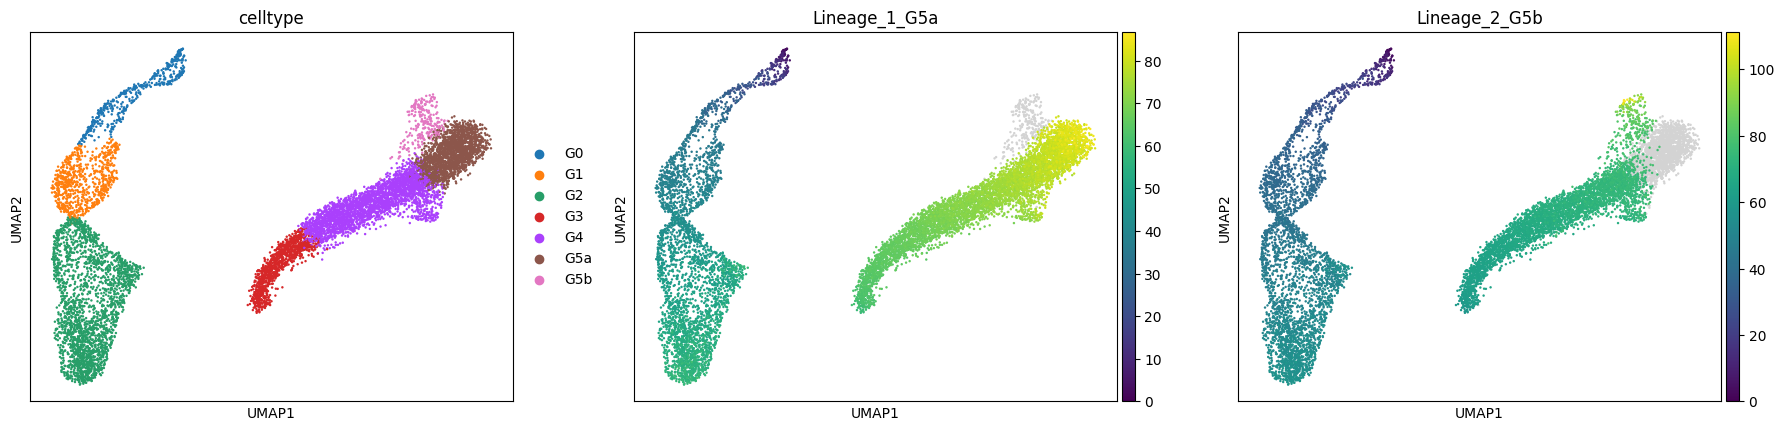

In [10]:
for column in slingshot["pseudotime_plot"].columns:
    ad_sling.obs[column] = slingshot["pseudotime_plot"][column]

sc.pl.umap(
    ad_sling,
    color=[
        stage_col,
        *slingshot["pseudotime_plot"].columns,
    ],
    ncols=3,
)

In [11]:
display(
    ad_sling.obs[
        [stage_col, *slingshot["pseudotime_plot"].columns]
    ]
    .groupby(stage_col, observed=True)
    .median()
)

,Lineage_1_G5a,Lineage_2_G5b
celltype,,
G0,23.354072,23.364032
G1,37.949598,38.054751
G2,51.517898,51.394079
G3,64.606635,64.203884
G4,71.310027,70.889340
G5a,78.617450,75.740502
G5b,79.103424,82.105743


In [12]:
display(
    ad_sling.obs[
        ["sample", stage_col, *slingshot["pseudotime_plot"].columns]
    ]
    .groupby(["sample", stage_col], observed=True)
    .median()
)

Lineage_1_G5a  Lineage_2_G5b
sample celltype                              
K1     G0            23.380026      23.380422
       G1            37.947145      38.014892
       G2            52.023126      51.940614
       G3            64.505169      64.026823
       G4            71.660036      71.437773
       G5a           78.511116      76.489887
       G5b                 NaN      85.748571
K2     G0            26.284470      26.309838
       G1            37.863470      37.744845
       G2            51.001155      50.906138
       G3            65.140876      64.539249
       G4            71.888273      71.281305
       G5a           79.303946      76.710475
       G5b                 NaN      82.629982
W1     G0            20.110570      20.111329
       G1            36.946738      36.911766
       G2            53.212008      53.133337
       G3            64.581637      64.070709
       G4            70.996837      70.570758
       G5a           78.199389      75.584528
       G5b                 NaN      81.147098
W2     G0            27.468878      27.491352
       G1            38.770896      38.747582
       G2            50.689273      50.463373
       G3            64.584269      64.083756
       G4            70.906902      70.255667
       G5a           78.400015      74.099038
       G5b           79.103424      80.832362

## 3.6 Compare trajectories across experimental conditions (optional)



When multiple experimental conditions are represented in the same Slingshot
trajectory, condiments can be used to test whether the conditions differ at
different levels of the trajectory [Roux de Bézieux, 2024].

Three complementary questions are evaluated:

1. **Differential topology** — whether the conditions are better represented by
   different trajectory structures.

2. **Differential progression** — whether cells from different conditions have
   different pseudotime distributions along the inferred lineages.

3. **Differential fate selection** — whether the relative assignment of cells
   to alternative lineages differs between conditions.

Fate-selection testing is only applicable when more than one lineage is
present.

These tests address trajectory-level differences and are conceptually distinct
from the downstream tradeSeq `conditionTest()`, which evaluates
condition-dependent gene-expression dynamics along the trajectory.

In [12]:
def RunCondimentsTests(
    adata,
    slingshot_result,
    condition_col="condition",
    topology_rep=100,
    progression_global=True,
    progression_lineages=True,
    fate_global=True,
    fate_pairwise=False,
):
    """
    Test condition-dependent topology, progression and fate selection with condiments.

    adata : AnnData --> Cells used for Slingshot trajectory inference.
    slingshot_result : dict --> Output from RunSlingshotTrajectory.
    condition_col : str --> Column containing experimental conditions.
    topology_rep : int --> Number of permutations used by topologyTest.
    progression_global : bool --> Return the global progression test.
    progression_lineages : bool --> Return lineage-specific progression tests.
    fate_global : bool --> Return the global fate-selection test.
    fate_pairwise : bool --> Return pairwise fate-selection tests.

    Returns
    -------
    dict --> Condiments topology, progression and optional fate-selection results.
    """
    import pandas as pd
    from rpy2 import robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter

    if condition_col not in adata.obs:
        raise KeyError(f"'{condition_col}' not found in adata.obs.")

    if "model" not in slingshot_result:
        raise KeyError("slingshot_result must contain 'model'.")

    cells = adata.obs_names.astype(str)
    conditions = adata.obs.loc[cells, condition_col].astype(str)

    if conditions.nunique() < 2:
        raise ValueError("At least two conditions are required.")

    ro.globalenv["condiments_sds"] = slingshot_result["model"]
    ro.globalenv["condiments_conditions"] = ro.StrVector(
        conditions.tolist()
    )

    ro.globalenv["topology_rep_run"] = int(topology_rep)
    ro.globalenv["progression_global_run"] = bool(progression_global)
    ro.globalenv["progression_lineages_run"] = bool(progression_lineages)
    ro.globalenv["fate_global_run"] = bool(fate_global)
    ro.globalenv["fate_pairwise_run"] = bool(fate_pairwise)

    ro.r("""
        suppressPackageStartupMessages({
            library(slingshot)
            library(condiments)
        })

        conditions_run <- factor(condiments_conditions)

        # STEP 1 — Differential topology
        topology_result <- topologyTest(
            condiments_sds,
            conditions_run,
            rep=topology_rep_run
        )

        # STEP 2A — Differential progression
        progression_result <- progressionTest(
            condiments_sds,
            conditions_run,
            global=progression_global_run,
            lineages=progression_lineages_run
        )

        # STEP 2B — Differential fate selection
        n_lineages_run <- ncol(
            slingCurveWeights(condiments_sds)
        )

        if (n_lineages_run > 1) {
            fate_result <- fateSelectionTest(
                condiments_sds,
                conditions_run,
                global=fate_global_run,
                pairwise=fate_pairwise_run
            )
        } else {
            fate_result <- NULL
        }
    """)

    # progressionTest and fateSelectionTest return data frames
    with localconverter(
        ro.default_converter + pandas2ri.converter
    ):
        progression = pd.DataFrame(
            ro.conversion.rpy2py(
                ro.globalenv["progression_result"]
            )
        )

        if len(slingshot_result["lineages"]) > 1:
            fate = pd.DataFrame(
                ro.conversion.rpy2py(
                    ro.globalenv["fate_result"]
                )
            )
        else:
            fate = None

    # topologyTest returns an R list; keep both useful values and raw object
    topology_raw = ro.globalenv["topology_result"]

    topology = {
        "method": list(ro.r("topology_result$method")),
        "statistic": list(ro.r("topology_result$statistic")),
        "pvalue": list(ro.r("topology_result$p.value")),
    }

    return {
        "topology": topology,
        "progression": progression,
        "fate_selection": fate,
        "topology_raw": topology_raw,
        "n_lineages": len(slingshot_result["lineages"]),
        "conditions": conditions.unique().tolist(),
    }

In [ ]:
# ###### 15MIN
# condiments_results = RunCondimentsTests(
#     adata=ad_sling,
#     slingshot_result=slingshot,
#     condition_col="condition",
#     topology_rep=100,
# )

# print("Differential topology:")
# print(condiments_results["topology"])

# print("\nDifferential progression:")
# display(condiments_results["progression"])

# print("\nDifferential fate selection:")
# if condiments_results["fate_selection"] is not None:
#     display(condiments_results["fate_selection"])
# else:
#     print("Not applicable: only one lineage.")

R callback write-console: Generating permuted trajectories
  


  |                                                  | 0 % ~calculating   |+                                                 | 1 % ~11m 20s       |+                                                 | 2 % ~11m 16s       |++                                                | 3 % ~11m 15s       |++                                                | 4 % ~11m 05s       |+++                                               | 5 % ~12m 32s       |+++                                               | 6 % ~12m 14s       |++++                                              | 7 % ~13m 01s       |++++                                              | 8 % ~12m 35s       |+++++                                             | 9 % ~13m 05s       |+++++                                             | 10% ~12m 56s       |++++++                                            | 11% ~12m 34s       |++++++                                            | 12% ~12m 14s       |+++++++                                           | 13% ~12m 

R callback write-console: Running KS-mean test
  


1 package is needed and is not installed. (randomForest). Would you like to try to install it now?
1: yes
2: no

Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair
Insira um item do menu, ou 0 para sair


## 3.7 Select the number of tradeSeq knots


tradeSeq models gene expression along pseudotime using negative-binomial
generalized additive models (NB-GAMs), in which smooth functions describe
changes in expression along each lineage [Van den Berge, 2020].

The flexibility of these smooth functions depends on the number of knots (`K`).
A small number of knots may fail to capture relevant expression dynamics,
whereas an unnecessarily large number increases model complexity.

tradeSeq therefore provides `evaluateK()`, which compares alternative values
of `K` using the Akaike Information Criterion (AIC). The objective is to select
a number of knots that provides an adequate bias-variance trade-off without
using more model complexity than necessary [Van den Berge, 2020].

Knots are positioned according to pseudotime and should be interpreted as
relative positions along the inferred trajectory, not as chronological time.

The number of knots should be selected before the genome-wide tradeSeq fit
and then kept fixed for downstream comparisons.

In [13]:
def EvaluateTradeSeqK(
    adata,
    slingshot_result,
    counts_layer,
    min_cells=20,
    k_values=(3, 4, 5, 6, 7),
    n_genes=200,
    seed=42,
):
    """
    Evaluate candidate tradeSeq knot numbers using gene-wise AIC.

    adata : AnnData --> Cells used in trajectory analysis.
    slingshot_result : dict --> Output from RunSlingshotTrajectory.
    counts_layer : str --> Layer containing raw counts.
    min_cells : int --> Minimum number of cells detecting a gene.
    k_values : tuple[int] --> Candidate numbers of knots.
    n_genes : int --> Number of genes sampled by evaluateK.
    seed : int --> Random seed for reproducible gene sampling.

    Returns
    -------
    DataFrame --> Gene-wise AIC values for each candidate number of knots.
    """
    import numpy as np
    import pandas as pd
    from scipy import sparse
    from rpy2 import robjects as ro
    from rpy2.robjects import numpy2ri
    from rpy2.robjects.conversion import localconverter

    if counts_layer not in adata.layers:
        raise KeyError(f"Layer '{counts_layer}' not found in adata.layers.")

    if min(k_values) < 3:
        raise ValueError("tradeSeq requires at least 3 knots.")

    cells = adata.obs_names.astype(str)

    # Use the exact Slingshot pseudotimes and weights stored previously
    pseudotime = slingshot_result["pseudotime"].reindex(cells)
    weights = slingshot_result["weights"].reindex(cells)

    if pseudotime.isna().any().any() or weights.isna().any().any():
        raise ValueError("Slingshot pseudotime or weights contain NA values.")

    # Filter extremely sparse genes
    X_all = adata.layers[counts_layer]

    if sparse.issparse(X_all):
        detected = np.asarray((X_all > 0).sum(axis=0)).ravel()
    else:
        detected = (np.asarray(X_all) > 0).sum(axis=0)

    keep = detected >= min_cells
    genes = adata.var_names[keep].astype(str)

    X = X_all[:, keep]

    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)

    X = X.T.tocoo()  # genes x cells

    print(f"Cells: {adata.n_obs}")
    print(f"Genes available: {len(genes)}")
    print(f"Genes evaluated: {min(n_genes, len(genes))}")
    print(f"K values: {list(k_values)}")

    # Transfer sparse counts
    ro.globalenv["k_i"] = ro.IntVector((X.row + 1).astype(int))
    ro.globalenv["k_j"] = ro.IntVector((X.col + 1).astype(int))
    ro.globalenv["k_x"] = ro.FloatVector(X.data.astype(float))
    ro.globalenv["k_ngenes"] = int(X.shape[0])
    ro.globalenv["k_ncells"] = int(X.shape[1])
    ro.globalenv["k_gene_names"] = ro.StrVector(genes.tolist())
    ro.globalenv["k_cell_names"] = ro.StrVector(cells.tolist())

    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["k_pseudotime"] = ro.conversion.py2rpy(
            pseudotime.to_numpy(dtype=float)
        )
        ro.globalenv["k_weights"] = ro.conversion.py2rpy(
            weights.to_numpy(dtype=float)
        )

    ro.globalenv["k_values"] = ro.IntVector(list(k_values))
    ro.globalenv["k_n_genes_eval"] = int(min(n_genes, len(genes)))
    ro.globalenv["k_seed"] = int(seed)

    ro.r("""
        suppressPackageStartupMessages({
            library(Matrix)
            library(tradeSeq)
        })

        counts_k <- sparseMatrix(
            i=k_i,
            j=k_j,
            x=k_x,
            dims=c(k_ngenes, k_ncells)
        )

        rownames(counts_k) <- k_gene_names
        colnames(counts_k) <- k_cell_names

        rownames(k_pseudotime) <- k_cell_names
        rownames(k_weights) <- k_cell_names

        set.seed(k_seed)

        aic_k <- evaluateK(
            counts=counts_k,
            pseudotime=k_pseudotime,
            cellWeights=k_weights,
            k=k_values,
            nGenes=k_n_genes_eval,
            plot=FALSE,
            verbose=FALSE,
            parallel=FALSE
        )
    """)

    with localconverter(ro.default_converter + numpy2ri.converter):
        aic_array = np.asarray(
            ro.conversion.rpy2py(ro.globalenv["aic_k"])
        )

    evaluated_genes = [str(x) for x in ro.r("rownames(aic_k)")]

    aic = pd.DataFrame(
        aic_array,
        index=evaluated_genes,
        columns=list(k_values),
    )

    ro.r("""
        rm(
            counts_k,
            k_i,
            k_j,
            k_x,
            aic_k
        )
        gc()
    """)

    return aic

In [14]:
def PlotTradeSeqK(aic_table):
    """
    Plot mean AIC across candidate tradeSeq knot numbers.

    aic_table : DataFrame --> Output from EvaluateTradeSeqK.

    Returns
    -------
    None --> Displays the AIC diagnostic plot.
    """
    import matplotlib.pyplot as plt

    mean_aic = aic_table.mean(axis=0)

    plt.figure(figsize=(6, 4))
    plt.plot(mean_aic.index, mean_aic.values, marker="o")
    plt.xlabel("Number of knots")
    plt.ylabel("Mean AIC")
    plt.title("tradeSeq knot evaluation")
    plt.xticks(mean_aic.index)
    plt.show()

Cells: 9755
Genes available: 16552
Genes evaluated: 200
K values: [3, 4, 5, 6, 7]


R callback write-console: Além disso:   
R callback write-console: Mensagens de aviso:
  
R callback write-console: 1:   
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  
R callback write-console: 2:   
R callback write-console: In asMethod(object) :  
R callback write-console: 
   
R callback write-console:  sparse->dense coercion: allocating vector of size 1.2 GiB
  


,3,4,5,6,7
Ltb,10788.950155,10791.102339,10737.369245,10732.684953,10729.989520
Ankrd13d,4331.703843,4334.655068,4333.814198,4333.144478,4332.452376
Uchl5,22729.580220,21883.064502,21913.912666,21804.807392,21756.565460
Kif11,19222.208665,19046.527851,18309.523292,17276.331199,17060.315409
Ncbp1,17571.329997,17567.148913,17573.502033,17571.451866,17562.546695


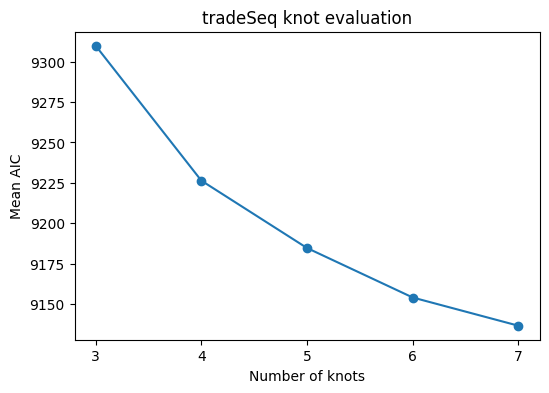

In [15]:
aic_k = EvaluateTradeSeqK(
    adata=ad_sling,
    slingshot_result=slingshot,
    counts_layer="QC_filtered",
    min_cells=20,
    k_values=(3, 4, 5, 6, 7),
    n_genes=200,
    seed=42,
)

display(aic_k.head())
PlotTradeSeqK(aic_k)